# 04 | Advanced Analysis

## Table of Contents

1. Advanced Analysis Setup
2. Employment vs. Customer Relationship Duration
3. Correlation Analysis by Credit Risk
4. Checking vs. Savings Balance
5. Financial Status and Credit Risk
6. High Risk Rate by Savings Balance Range
7. High Risk Rate by Checking Balance Range
8. High Risk Rate by Employment Duration
9. High Risk Rate by Customer Relationship Duration
10. Customer and Employment Duration Heatmap
11. Chi-Square Test
12. Key Findings

In [7]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# === Advanced Analysis Setup ===

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = "Data/Credit_Risk_Data.xlsx"
base_df = pd.read_excel(file_path, sheet_name=0)

# Clean column names
base_df.columns = base_df.columns.str.strip()

# Standardize gender values
base_df["Gender"] = base_df["Gender"].str.strip().str.upper()

# Set consistent chart colors
risk_colors = {
    "High": "#E76F51",  # Coral
    "Low": "#2A9D8F"    # Teal
}

print("Advanced analysis dataset loaded successfully!")
print("Dataset shape:", base_df.shape)

Advanced analysis dataset loaded successfully!
Dataset shape: (425, 12)


c:\Users\selen\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


## 4.1 Employment Duration vs. Customer Relationship Duration

=== Employment vs. Customer Relationship Duration ===


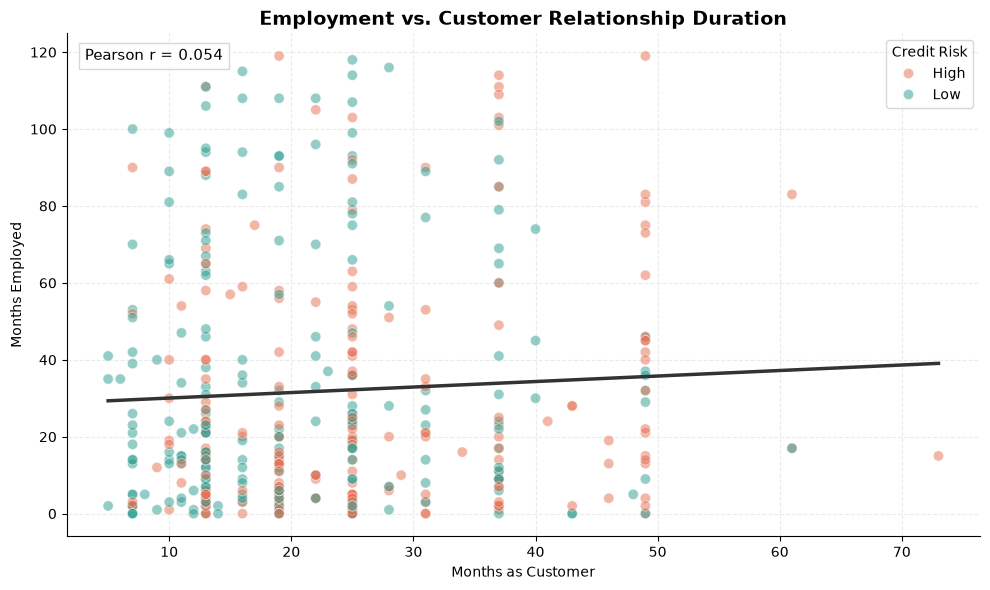

Pearson Correlation: 0.054


In [9]:
print("=== Employment vs. Customer Relationship Duration ===")

# Calculate Pearson correlation between the two variables
correlation = base_df["Months Customer"].corr(
    base_df["Months Employed"]
)

# Create the scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=base_df,
    x="Months Customer",
    y="Months Employed",
    hue="Credit Risk",
    hue_order=["High", "Low"],
    palette=risk_colors,
    alpha=0.5,              # Reduce opacity to show overlapping points
    s=55,
    ax=ax
)

# Add an overall linear trend line
sns.regplot(
    data=base_df,
    x="Months Customer",
    y="Months Employed",
    scatter=False,          # Show only the trend line
    color="#333333",
    ci=None,                # Hide confidence interval shading
    line_kws={
        "linewidth": 2.5,
        "label": "Overall Trend"
    },
    ax=ax
)

# Add chart title and axis labels
ax.set_title(
    "Employment vs. Customer Relationship Duration",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Months as Customer")
ax.set_ylabel("Months Employed")

# Display correlation coefficient on the chart
ax.text(
    0.02, 0.97,
    f"Pearson r = {correlation:.3f}",
    transform=ax.transAxes,
    fontsize=11,
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9
    )
)

# Improve readability
ax.legend(title="Credit Risk")
ax.grid(linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Print correlation value
print(f"Pearson Correlation: {correlation:.3f}")

**Observation: Employment vs. Customer Relationship Duration**

The Pearson correlation coefficient is 0.054, indicating almost no linear relationship between employment duration and customer relationship duration.

The trend line slopes slightly upward, but the relationship is extremely weak.

Borrowers with similar customer relationship durations have widely different employment histories.

High Risk and Low Risk borrowers overlap throughout the chart, with no clear separation between the two groups.

This suggests that knowing how long someone has been a customer does not necessarily tell us much about their employment history.

Although both variables showed interesting differences when analyzed individually, they do not appear to have a meaningful linear relationship with each other. However, this does not mean they are unimportant for predicting credit risk.

In [10]:
print("=== Correlation by Credit Risk ===")

# Calculate Pearson correlation separately for each risk group
# groupby() divides the data into High Risk and Low Risk borrowers
for risk, group in base_df.groupby("Credit Risk"):

    # Calculate correlation within this group
    correlation = group["Months Customer"].corr(
        group["Months Employed"]
    )

    # Display the correlation and number of borrowers
    print(f"{risk} Risk:")
    print(f"  Borrowers: {len(group)}")
    print(f"  Pearson r: {correlation:.3f}")
    print()

=== Correlation by Credit Risk ===
High Risk:
  Borrowers: 211
  Pearson r: 0.116

Low Risk:
  Borrowers: 214
  Pearson r: 0.040



**Observation: Correlation by Credit Risk**

High Risk borrowers have a Pearson correlation of 0.116, compared to 0.040 for Low Risk borrowers.

Both groups show very weak positive linear relationships between employment duration and customer relationship duration.

Although the correlation is slightly higher among High Risk borrowers, neither group shows a strong relationship.

This supports our earlier observation that these two variables are largely independent in terms of their linear relationship, regardless of credit risk classification.

## 4.2 Financial Factors: Checking vs. Savings Balance

=== High Risk Rate by Checking and Savings Status ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Financial Status,,,,
Zero Checking / Zero Savings,10,3,13,76.9
Positive Checking / Positive Savings,70,55,125,56.0
Zero Checking / Positive Savings,118,120,238,49.6
Positive Checking / Zero Savings,13,36,49,26.5


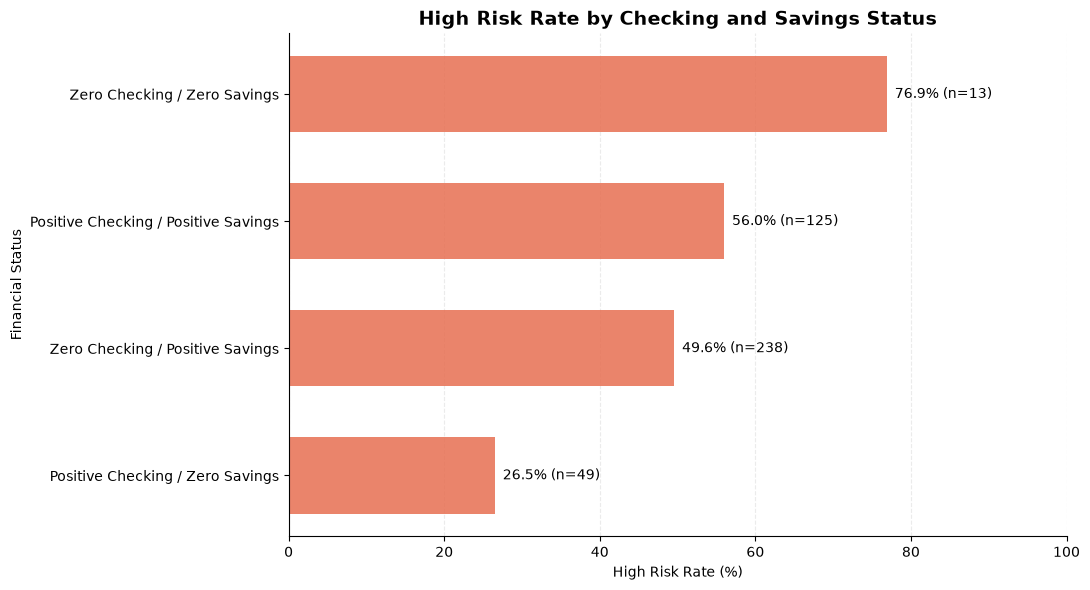


Pearson Correlation (original balances): 0.020


In [12]:
print("=== High Risk Rate by Checking and Savings Status ===")

# Create categories based on whether each balance is zero or positive
# This does not change the original Checking or Savings values
base_df["Financial Status"] = base_df.apply(
    lambda row: (
        ("Zero Checking" if row["Checking"] == 0 else "Positive Checking")
        + " / "
        + ("Zero Savings" if row["Savings"] == 0 else "Positive Savings")
    ),
    axis=1
)

# Count High Risk and Low Risk borrowers in each category
financial_risk = pd.crosstab(
    base_df["Financial Status"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and percentage classified as High Risk
financial_risk["Total"] = financial_risk["High"] + financial_risk["Low"]

financial_risk["High Risk Rate (%)"] = (
    financial_risk["High"] / financial_risk["Total"] * 100
)

# Sort categories from highest to lowest high-risk rate
financial_risk = financial_risk.sort_values(
    "High Risk Rate (%)",
    ascending=False
)

# Display the results
display(financial_risk.round(1))

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    financial_risk.index,
    financial_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    height=0.6
)

# Display percentages and sample sizes beside each bar
for bar, rate, total in zip(
    bars,
    financial_risk["High Risk Rate (%)"],
    financial_risk["Total"]
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}% (n={total})",
        va="center",
        fontsize=10
    )

# Add chart title and labels
ax.set_title(
    "High Risk Rate by Checking and Savings Status",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("High Risk Rate (%)")
ax.set_ylabel("Financial Status")

# Improve readability
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Keep the original correlation as a supporting statistic
correlation = base_df["Checking"].corr(base_df["Savings"])
print(f"\nPearson Correlation (original balances): {correlation:.3f}")

**Observation: Checking and Savings Status by Credit Risk**

Borrowers with zero checking and zero savings have the highest high-risk rate at 76.9%, although this group only includes 13 borrowers.

Surprisingly, borrowers with positive checking balances but zero savings have the lowest high-risk rate at 26.5%.

Borrowers with positive balances in both accounts have a high-risk rate of 56.0%, compared to 49.6% for those with zero checking but positive savings.

The Pearson correlation between checking and savings balances is only 0.020, indicating almost no linear relationship between the two amounts.

These findings suggest that the combination of checking and savings status may provide useful information beyond looking at each balance separately.

For our dashboard, comparing financial status combinations could help identify customer segments worth investigating further. However, we should consider sample sizes and other borrower characteristics before making lending decisions.

## 4.3 Savings Balance Ranges and Credit Risk

=== High Risk Rate by Savings Balance Range ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Savings Range,,,,
$0,23,39,62,37.1
$1–$500,61,61,122,50.0
"$501–$1,000",89,66,155,57.4
"$1,001–$5,000",24,19,43,55.8
"Over $5,000",14,29,43,32.6


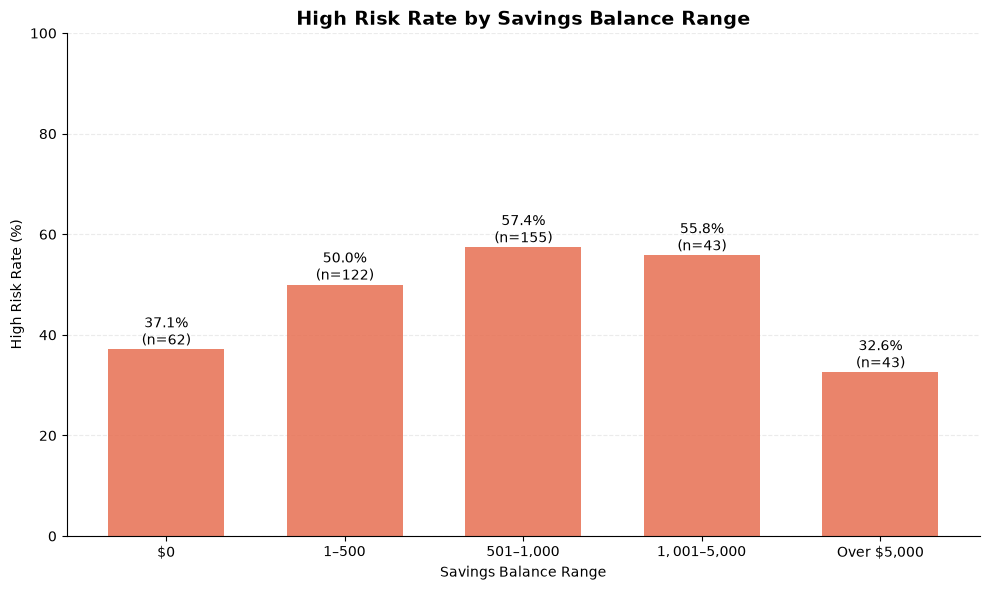

In [13]:
print("=== High Risk Rate by Savings Balance Range ===")

# Divide savings balances into meaningful ranges
# Zero is kept separate because many borrowers have no savings
savings_bins = [-1, 0, 500, 1000, 5000, float("inf")]

savings_labels = [
    "$0",
    "$1–$500",
    "$501–$1,000",
    "$1,001–$5,000",
    "Over $5,000"
]

# Create a new category without changing the original savings values
base_df["Savings Range"] = pd.cut(
    base_df["Savings"],
    bins=savings_bins,
    labels=savings_labels
)

# Count High Risk and Low Risk borrowers in each range
savings_risk = pd.crosstab(
    base_df["Savings Range"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and high-risk percentage
savings_risk["Total"] = savings_risk["High"] + savings_risk["Low"]

savings_risk["High Risk Rate (%)"] = (
    savings_risk["High"] / savings_risk["Total"] * 100
)

# Display results in savings order
display(savings_risk.round(1))

# Create a bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    savings_risk.index.astype(str),
    savings_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    width=0.65
)

# Add percentage and sample size labels
for bar, rate, total in zip(
    bars,
    savings_risk["High Risk Rate (%)"],
    savings_risk["Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        fontsize=10
    )

# Add title and labels
ax.set_title(
    "High Risk Rate by Savings Balance Range",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Savings Balance Range")
ax.set_ylabel("High Risk Rate (%)")

# Improve readability
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Savings Balance Ranges and Credit Risk**

The relationship between savings balance and credit risk is not consistent across the different balance ranges.

Borrowers with $501–$1,000 in savings have the highest high-risk rate at 57.4%, followed by those with $1,001–$5,000 at 55.8%.

Borrowers with more than $5,000 in savings have the lowest high-risk rate at 32.6%.

Interestingly, borrowers with no savings have a relatively low high-risk rate of 37.1%, compared to those with smaller positive savings balances.

The results suggest that having a higher savings balance does not always correspond to lower credit risk, although the group with the largest savings balances shows a lower rate.

This highlights the importance of examining actual balance amounts rather than simply categorizing customers as having zero or positive savings. Other financial and personal characteristics may also influence these patterns.

The high-risk rates show a roughly inverted U-shaped pattern across the savings categories, increasing in the lower ranges before declining among borrowers with higher savings balances. This pattern is exploratory and would need further analysis to confirm.

## 4.4 Checking Balance Ranges and Credit Risk

=== High Risk Rate by Checking Balance Range ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Checking Range,,,,
$0,128,123,251,51.0
$1–$500,30,31,61,49.2
"$501–$1,000",39,30,69,56.5
"$1,001–$5,000",2,14,16,12.5
"Over $5,000",12,16,28,42.9


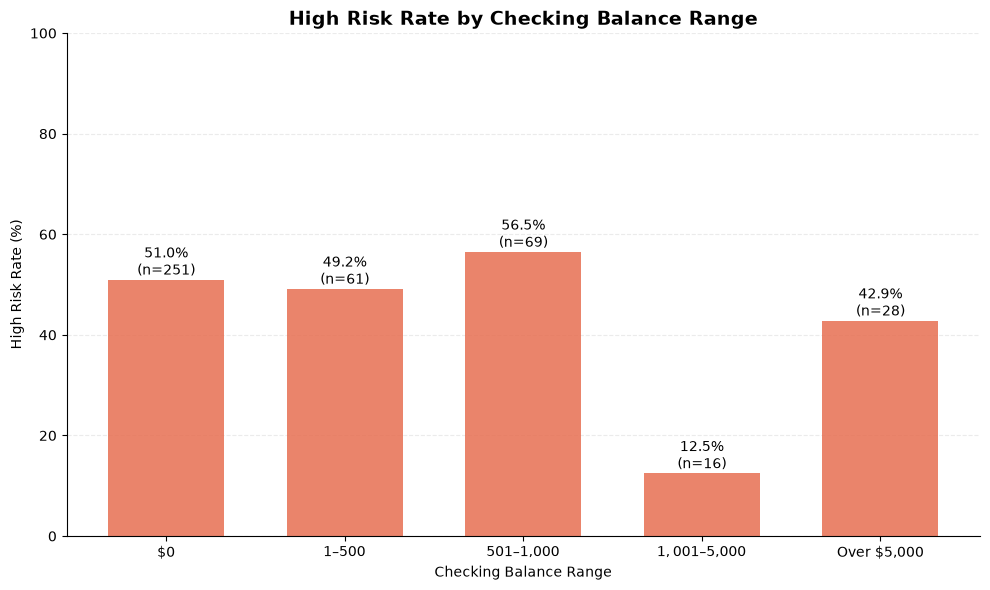

In [14]:
print("=== High Risk Rate by Checking Balance Range ===")

# Create checking balance ranges
# Keep zero balances separate from positive balances
checking_bins = [-1, 0, 500, 1000, 5000, float("inf")]

checking_labels = [
    "$0",
    "$1–$500",
    "$501–$1,000",
    "$1,001–$5,000",
    "Over $5,000"
]

# Categorize borrowers without changing original checking balances
base_df["Checking Range"] = pd.cut(
    base_df["Checking"],
    bins=checking_bins,
    labels=checking_labels
)

# Count High Risk and Low Risk borrowers in each range
checking_risk = pd.crosstab(
    base_df["Checking Range"],
    base_df["Credit Risk"]
)

# Calculate sample size and high-risk percentage
checking_risk["Total"] = checking_risk["High"] + checking_risk["Low"]

checking_risk["High Risk Rate (%)"] = (
    checking_risk["High"] / checking_risk["Total"] * 100
)

# Display the table in checking balance order
display(checking_risk.round(1))

# Create a bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    checking_risk.index.astype(str),
    checking_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    width=0.65
)

# Add percentage and sample size above each bar
for bar, rate, total in zip(
    bars,
    checking_risk["High Risk Rate (%)"],
    checking_risk["Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        fontsize=10
    )

# Add chart title and labels
ax.set_title(
    "High Risk Rate by Checking Balance Range",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Checking Balance Range")
ax.set_ylabel("High Risk Rate (%)")

# Improve readability
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Checking Balance Ranges and Credit Risk**

The high-risk rate varies across checking balance ranges without showing a consistent increasing or decreasing pattern.

Borrowers with $501–$1,000 in checking have the highest high-risk rate at 56.5%.

The rate drops sharply to 12.5% for borrowers with $1,001–$5,000, although this group contains only 16 borrowers.

Interestingly, the rate increases again to 42.9% for borrowers with more than $5,000.

Most borrowers have zero checking balance (251 out of 425), and their high-risk rate is 51.0%.

Compared to savings balances, checking balances show a more irregular pattern. This suggests that checking balance alone may not be enough to explain credit risk, especially when some balance ranges contain relatively few borrowers.

## 4.5 Employment Duration Ranges and Credit Risk

=== High Risk Rate by Employment Duration ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Employment Range,,,,
0 Months,13,12,25,52.0
1–12 Months,70,56,126,55.6
13–36 Months,65,73,138,47.1
37–60 Months,31,22,53,58.5
Over 60 Months,32,51,83,38.6


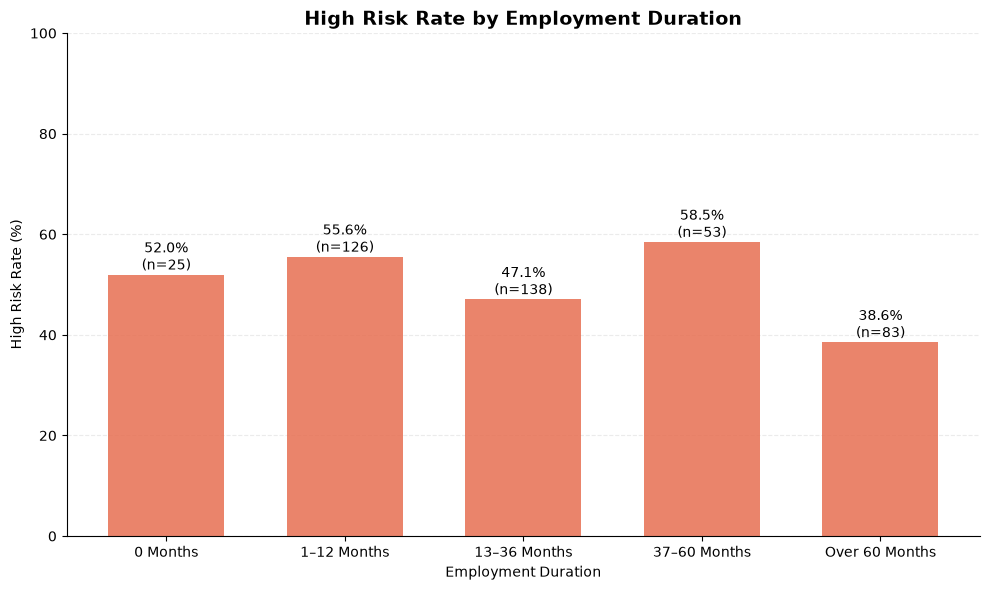

In [15]:
print("=== High Risk Rate by Employment Duration ===")

# Group employment duration into ranges (in months)
employment_bins = [-1, 0, 12, 36, 60, float("inf")]

employment_labels = [
    "0 Months",
    "1–12 Months",
    "13–36 Months",
    "37–60 Months",
    "Over 60 Months"
]

# Create employment categories without changing the original values
base_df["Employment Range"] = pd.cut(
    base_df["Months Employed"],
    bins=employment_bins,
    labels=employment_labels
)

# Count borrowers in each risk category
employment_risk = pd.crosstab(
    base_df["Employment Range"],
    base_df["Credit Risk"]
)

# Calculate total borrowers and high-risk percentage
employment_risk["Total"] = employment_risk["High"] + employment_risk["Low"]

employment_risk["High Risk Rate (%)"] = (
    employment_risk["High"] / employment_risk["Total"] * 100
)

# Display the results
display(employment_risk.round(1))

# Create a bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    employment_risk.index.astype(str),
    employment_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    width=0.65
)

# Add percentages and sample sizes above each bar
for bar, rate, total in zip(
    bars,
    employment_risk["High Risk Rate (%)"],
    employment_risk["Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        fontsize=10
    )

# Add chart title and labels
ax.set_title(
    "High Risk Rate by Employment Duration",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Employment Duration")
ax.set_ylabel("High Risk Rate (%)")

# Improve readability
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Employment Duration and Credit Risk**

The high-risk rate fluctuates across employment duration ranges rather than showing a consistent trend.

Borrowers employed for 37–60 months have the highest high-risk rate at 58.5%, while those employed for more than 60 months have the lowest rate at 38.6%.

Interestingly, borrowers with 13–36 months of employment have a lower high-risk rate than those employed for 37–60 months.

Although longer employment does not consistently correspond to lower credit risk, the group with more than five years of employment appears to have a lower risk rate.

These findings suggest that employment duration alone may not be enough to explain credit risk. Other borrower characteristics could be influencing the differences between groups.

## 4.6 Customer Relationship Duration and Credit Risk

=== High Risk Rate by Customer Relationship Duration ===


Credit Risk,High,Low,Total,High Risk Rate (%)
Customer Duration Range,,,,
0–12 Months,15,51,66,22.7
13–24 Months,84,87,171,49.1
25–36 Months,59,44,103,57.3
37–48 Months,30,24,54,55.6
Over 48 Months,23,8,31,74.2


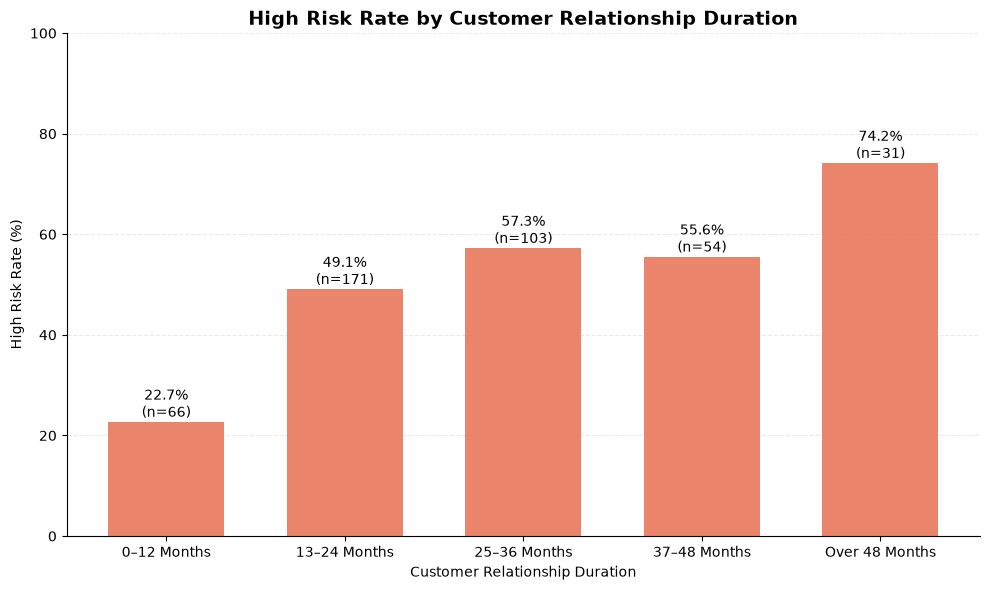

In [16]:
print("=== High Risk Rate by Customer Relationship Duration ===")

# Group customer relationship duration into ranges (months)
customer_bins = [-1, 12, 24, 36, 48, float("inf")]

customer_labels = [
    "0–12 Months",
    "13–24 Months",
    "25–36 Months",
    "37–48 Months",
    "Over 48 Months"
]

# Create duration categories without changing the original data
base_df["Customer Duration Range"] = pd.cut(
    base_df["Months Customer"],
    bins=customer_bins,
    labels=customer_labels
)

# Count High Risk and Low Risk borrowers in each group
customer_risk = pd.crosstab(
    base_df["Customer Duration Range"],
    base_df["Credit Risk"]
)

# Calculate group sizes and high-risk percentages
customer_risk["Total"] = customer_risk["High"] + customer_risk["Low"]

customer_risk["High Risk Rate (%)"] = (
    customer_risk["High"] / customer_risk["Total"] * 100
)

# Display results
display(customer_risk.round(1))

# Create a bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    customer_risk.index.astype(str),
    customer_risk["High Risk Rate (%)"],
    color="#E76F51",
    alpha=0.85,
    width=0.65
)

# Display percentages and sample sizes
for bar, rate, total in zip(
    bars,
    customer_risk["High Risk Rate (%)"],
    customer_risk["Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        fontsize=10
    )

# Add chart title and labels
ax.set_title(
    "High Risk Rate by Customer Relationship Duration",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Customer Relationship Duration")
ax.set_ylabel("High Risk Rate (%)")

# Improve readability
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Observation: Customer Relationship Duration and Credit Risk**

Unlike several other variables we've analyzed, customer relationship duration shows a fairly clear upward pattern in high-risk rates.

Borrowers who have been customers for 0–12 months have the lowest high-risk rate at 22.7%, while those with relationships longer than 48 months have the highest rate at 74.2%.

The rate generally increases with customer relationship duration, although there is a slight decrease between 25–36 months and 37–48 months.

This is interesting because we might normally expect longer customer relationships to be associated with greater financial stability and lower credit risk.

One possible explanation is that customer behavior or borrowing patterns change over time, but we would need additional information to investigate this.

Customer relationship duration may be an important variable to explore further in our predictive model. However, this association does not mean that being a customer longer causes higher credit risk.

## 4.7 Customer Relationship and Employment Duration: Combined Risk

=== High Risk Rate by Customer and Employment Duration ===


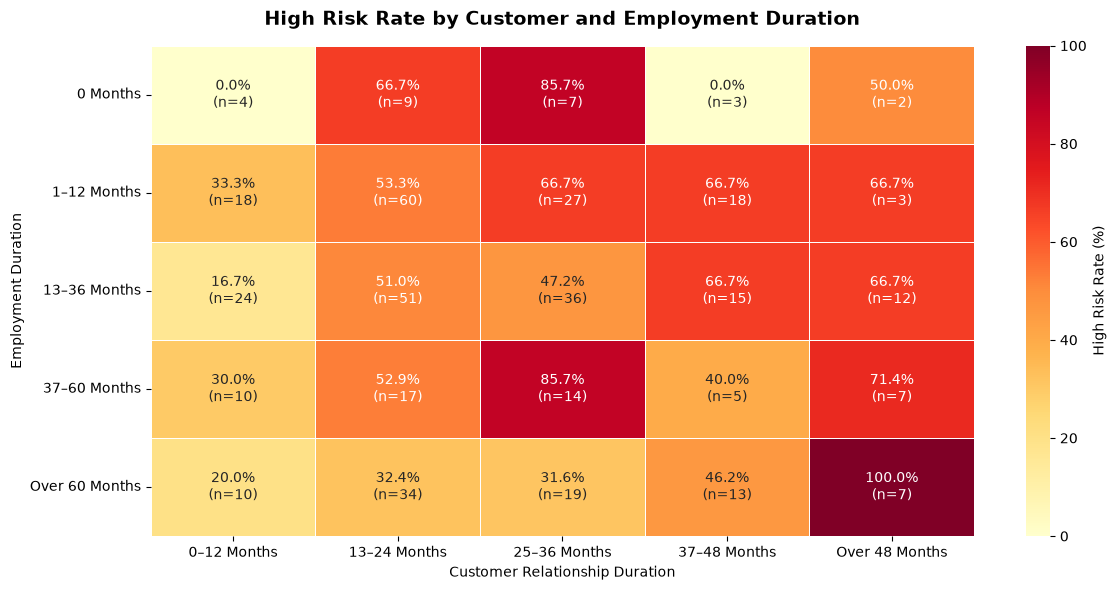

In [17]:
print("=== High Risk Rate by Customer and Employment Duration ===")

# Use the duration categories we created in Sections 4.5 and 4.6
# Create a binary indicator: 1 = High Risk, 0 = Low Risk
base_df["High Risk Indicator"] = (
    base_df["Credit Risk"] == "High"
).astype(int)

# Calculate the high-risk percentage for each combination
risk_heatmap = base_df.pivot_table(
    index="Employment Range",
    columns="Customer Duration Range",
    values="High Risk Indicator",
    aggfunc="mean",
    observed=False
) * 100

# Count borrowers in each combination
sample_counts = base_df.pivot_table(
    index="Employment Range",
    columns="Customer Duration Range",
    values="High Risk Indicator",
    aggfunc="count",
    observed=False
)

# Create labels showing both percentage and sample size
# Leave empty combinations blank
labels = risk_heatmap.copy().astype(object)

for row in risk_heatmap.index:
    for col in risk_heatmap.columns:
        n = sample_counts.loc[row, col]
        rate = risk_heatmap.loc[row, col]

        labels.loc[row, col] = (
            f"{rate:.1f}%\n(n={n})"
            if n > 0 else ""
        )

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    risk_heatmap,
    annot=labels,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    mask=sample_counts.eq(0),
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "High Risk Rate (%)"},
    ax=ax
)

# Add chart title and labels
ax.set_title(
    "High Risk Rate by Customer and Employment Duration",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Customer Relationship Duration")
ax.set_ylabel("Employment Duration")

# Improve label readability
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Observation: Customer Relationship and Employment Duration**

The heatmap shows that customer relationship duration appears to have a more consistent association with credit risk than employment duration.

Borrowers with shorter customer relationships generally have lower high-risk rates across different employment groups.

As customer relationship duration increases, high-risk rates tend to increase, although the pattern is not consistent in every group.

Employment duration does not show a clear relationship with credit risk when combined with customer relationship duration.

Some combinations have very small sample sizes, making their percentages less reliable. For example, the 100% high-risk rate among customers with more than 48 months of customer history and more than 60 months of employment is based on only 7 borrowers.

Overall, this analysis supports our earlier finding that customer relationship duration may be an important factor to investigate further. However, we need additional statistical analysis to determine whether the relationship remains meaningful after accounting for other variables.

## 4.8 Statistical Testing: Customer Duration and Credit Risk

In [19]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   --- ------------------------------------ 2.9/36.6 MB 16.0 MB/s eta 0:00:03
   ------ --------------------------------- 6.3/36.6 MB 16.0 MB/s eta 0:00:02
   -------- ------------------------------- 7.6/36.6 MB 13.8 MB/s eta 0:00:03
   -------- ------------------------------- 7.9/36.6 MB 12.2 MB/s eta 0:00:03
   --------- ------------------------------ 8.9/36.6 MB 8.8 MB/s eta 0:00:04
   ------------ --------------------------- 11.0/36.6 MB 8.9 MB/s eta 0:00:03
   -------------- ------------------------- 13.1/36.6 MB 9.0 MB/s eta 0:00:03
   ---------------- ----------------------- 15.5/36.6 MB 9.3 MB/s eta 0:00:03
   ------------------ --------------------- 16.5/36.6 MB 8.8 MB/s eta 0:00:03
   ------------------- -------------------- 17.8/36.6 MB 8.6 MB/s eta 0:00:03
   -------------------- ------------------- 18.6/36.6 MB 8.2 MB/s eta 0:00:03
   -------------------- ------------------- 19.1/36.6 MB 7.6 MB/s eta 0:0


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
print("=== Chi-Square Test: Customer Duration vs. Credit Risk ===")

# Import the statistical test
from scipy.stats import chi2_contingency

# Create a table of borrower counts by duration and credit risk
contingency_table = pd.crosstab(
    base_df["Customer Duration Range"],
    base_df["Credit Risk"]
)

display(contingency_table)

# Perform the chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Display the test results
print(f"Chi-Square Statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of Freedom: {dof}")

# Check whether the result is statistically significant
alpha = 0.05

if p_value < alpha:
    print("\nResult: Statistically significant association.")
else:
    print("\nResult: No statistically significant association detected.")

# Check the smallest expected count for test reliability
print(f"Minimum Expected Count: {expected.min():.2f}")

=== Chi-Square Test: Customer Duration vs. Credit Risk ===


Credit Risk,High,Low
Customer Duration Range,,
0–12 Months,15,51
13–24 Months,84,87
25–36 Months,59,44
37–48 Months,30,24
Over 48 Months,23,8


Chi-Square Statistic: 29.778
P-value: 0.000005
Degrees of Freedom: 4

Result: Statistically significant association.
Minimum Expected Count: 15.39


**Observation: Chi-Square Test**

The chi-square test found a statistically significant association between customer relationship duration and credit risk (χ² = 29.778, p < 0.001).

Since the p-value is below 0.05, we reject the null hypothesis that the two variables are independent.

The minimum expected count was 15.39, indicating that the expected-frequency assumption was satisfied.

Combined with our earlier chart, this provides stronger evidence that customer relationship duration is associated with differences in credit risk.

This is one of our more meaningful findings so far. However, statistical significance does not necessarily imply causation, and further modeling is needed to understand its predictive value.